# Carolina Panthers: is a 10% private-equity stake at $8.1B a good investment?

**Vincent Huang** · UNC Charlotte, BSBA Finance '29 · October 2026

Since 2024 the NFL has let approved private-equity firms own 3–10% of a team (six-year minimum hold, no control). Forbes values the Panthers at **$8.1B**. This notebook asks whether a PE firm should buy 10% at that price, using three methods:

1. a 10-year DCF of owner cash flows (two terminal methods, two sensitivity grids),
2. nine NFL control and minority transactions from 2022–2026, and
3. a bear/base/bull IRR model for the stake.

All team financials are **Forbes estimates**; NFL teams are private. Every assumption lives in `panthers_valuation/inputs.py` with its source. The same model exists in Excel (`Panthers_Valuation_Model.xlsx`); `tests/` checks the two agree.

In [1]:
import pandas as pd
from panthers_valuation import Inputs, project, dcf_value, sensitivity, load_comps, comps_summary, implied_values
from panthers_valuation.pe_stake import pe_table, breakeven_growth, breakeven_discount
from panthers_valuation import charts
from pathlib import Path
from IPython.display import Image, display
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
OUT = Path("output"); OUT.mkdir(exist_ok=True)
inp = Inputs()
pd.Series(inp.to_dict()).to_frame("value")

,value
forbes_value,"8,100.0"
sportico_value,"8,070.0"
revenue_2025,646.0
ebitda_2025,88.0
player_costs_2025,366.0
debt_pct_of_value,0.0
tepper_price_2018,"2,280.0"
league_avg_value,"9,500.0"
league_avg_ev_rev,13.4
national_rev_2025,455.0


## 1. Where the $8.1B came from

Value compounded ~17% a year since 2017 while revenue grew ~6%. The revenue multiple went from 5.8x to 12.5x; the multiple, not the P&L, did the work.

,season,value_mm,revenue_mm,operating_income_mm,player_expenses_mm,ev_rev,margin
0,2017,2300,396,62,218,5.8,0.2
1,2018,2400,424,78,223,5.7,0.2
2,2019,2600,447,96,224,5.8,0.2
3,2020,2900,351,-22,241,8.3,-0.1
4,2021,3600,501,139,224,7.2,0.3
5,2022,4100,530,72,282,7.7,0.1
6,2023,4500,574,109,284,7.8,0.2
7,2024,5700,588,36,369,9.7,0.1
8,2025,8100,646,88,366,12.5,0.1


Value CAGR 2017-25: 17.0%   Revenue CAGR: 6.3%


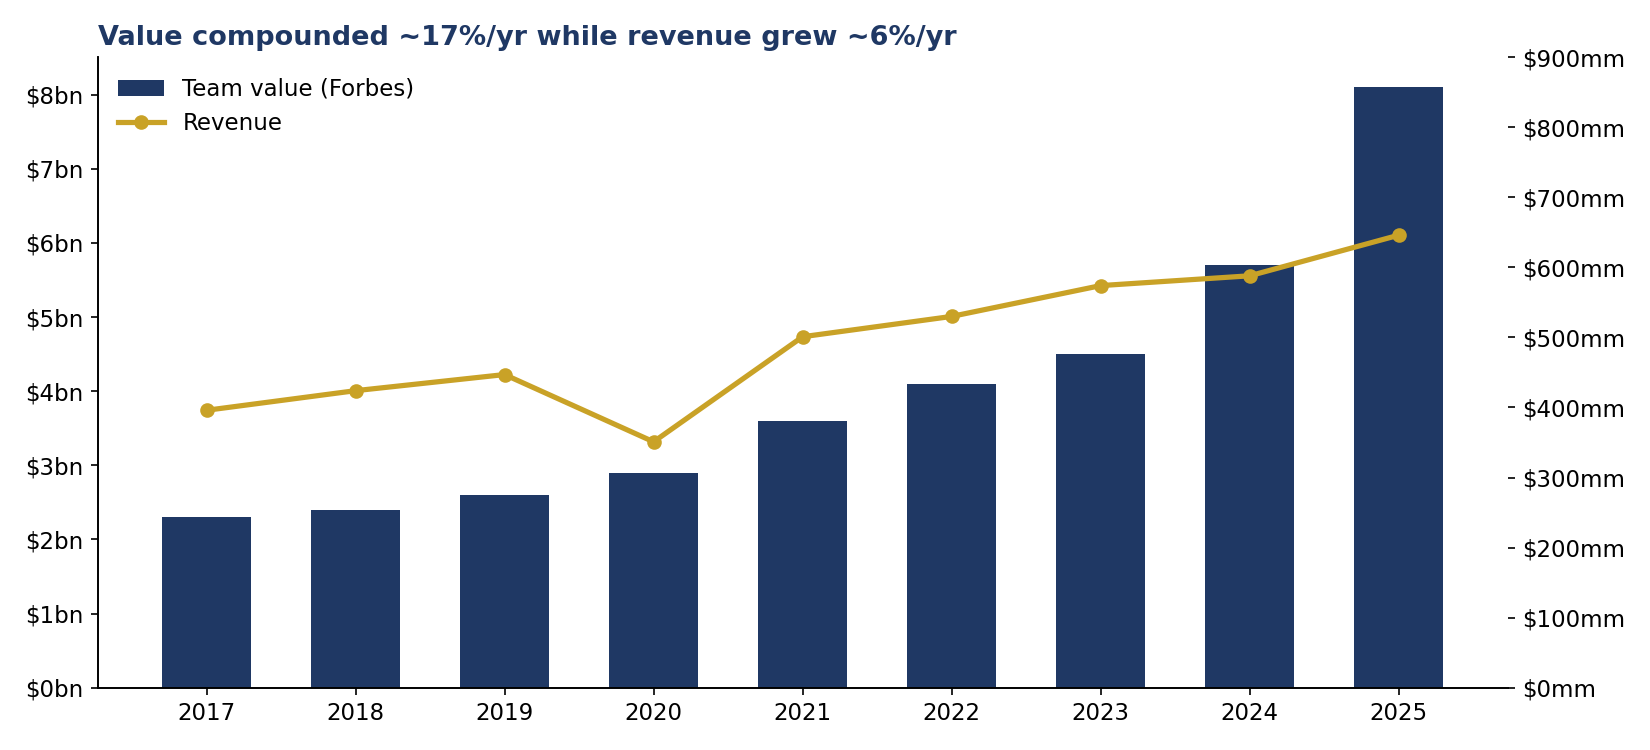

In [2]:
hist = pd.read_csv("data/panthers_history.csv")
hist["ev_rev"] = hist.value_mm / hist.revenue_mm
hist["margin"] = hist.operating_income_mm / hist.revenue_mm
display(hist)
print(f"Value CAGR 2017-25: {(hist.value_mm.iloc[-1]/hist.value_mm.iloc[0])**(1/8)-1:.1%}   Revenue CAGR: {(hist.revenue_mm.iloc[-1]/hist.revenue_mm.iloc[0])**(1/8)-1:.1%}")
display(Image(charts.history(hist, OUT / "history.png")))

## 2. DCF: what the cash flows are worth

National (shared league) revenue is ~70% of the total and grows with the media deals, with an assumed 10% step-up after the 2029 opt-out. Local revenue grows 3% with a 20% lift when the renovated Bank of America Stadium opens in 2028. Player costs track the salary cap. Owner cash flow is after a 25% tax approximation, maintenance capex, and Tepper Sports' stadium contributions.

In [3]:
df = project(inp)
display(df[["national","local","revenue","player","other_opex","ebitda","margin","tax","stadium_capex","fcf"]].round(1))
val = dcf_value(inp, df)
print(f"EV, exit multiple ({inp.exit_multiple:.0f}x 2035 revenue): ${val['ev_exit']:,.0f}mm  ({val['ev_exit_multiple_of_2025_rev']:.1f}x 2025 revenue)")
print(f"EV, perpetuity growth ({inp.terminal_growth:.0%}):        ${val['ev_gordon']:,.0f}mm")
print(f"Forbes value / cash-flow value:            {val['scarcity_premium']:.1f}x")

,national,local,revenue,player,other_opex,ebitda,margin,tax,stadium_capex,fcf
year,,,,,,,,,,
2025,455.0,191.0,646.0,-366.0,-192.0,88.0,0.1,0.0,0.0,NaN
2026,482.3,196.7,679.0,-388.0,-197.8,93.3,0.1,-23.3,-37.5,22.5
2027,511.2,202.6,713.9,-411.2,-203.7,98.9,0.1,-24.7,-37.5,26.7
2028,541.9,250.5,792.4,-435.9,-209.8,146.6,0.2,-36.7,-37.5,62.5
2029,574.4,258.0,832.4,-462.1,-216.1,154.2,0.2,-38.6,-37.5,68.2
2030,663.5,265.7,929.2,-489.8,-222.6,216.8,0.2,-54.2,-38.0,114.6
2031,696.6,273.7,970.3,-519.2,-229.3,221.9,0.2,-55.5,-38.0,118.4
2032,731.5,281.9,"1,013.4",-550.3,-236.1,226.9,0.2,-56.7,-38.0,122.2
2033,768.0,290.3,"1,058.4",-583.3,-243.2,231.8,0.2,-58.0,-38.0,125.9


EV, exit multiple (12x 2035 revenue): $6,980mm  (10.8x 2025 revenue)
EV, perpetuity growth (4%):        $2,163mm
Forbes value / cash-flow value:            3.7x


**Reading this:** on cash flow alone the team is worth about $2.2B. The market pays 3.7x that. Everything above the cash-flow value is a bet on scarcity (32 teams, few for sale) and on the next buyer paying a higher multiple.

,10,11,12,13,14
discount_rate,,,,,
0.1,"6,466.0","7,053.0","7,640.0","8,227.0","8,814.0"
0.1,"5,911.0","6,445.0","6,980.0","7,515.0","8,050.0"
0.1,"5,408.0","5,896.0","6,384.0","6,872.0","7,360.0"
0.1,"4,954.0","5,399.0","5,844.0","6,289.0","6,735.0"


,0.0,0.0,0.0,0.0,0.1
discount_rate,,,,,
0.1,"2,336.0","2,594.0","2,939.0","3,421.0","4,144.0"
0.1,"1,831.0","1,978.0","2,163.0","2,401.0","2,718.0"
0.1,"1,495.0","1,588.0","1,699.0","1,835.0","2,005.0"
0.1,"1,256.0","1,318.0","1,390.0","1,476.0","1,578.0"


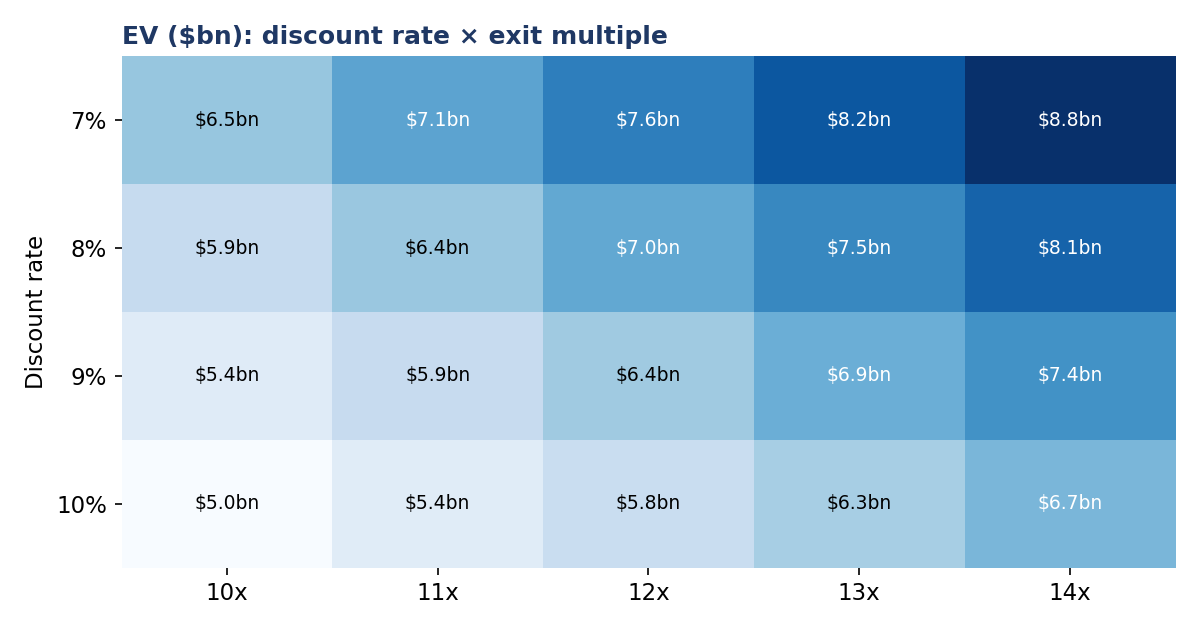

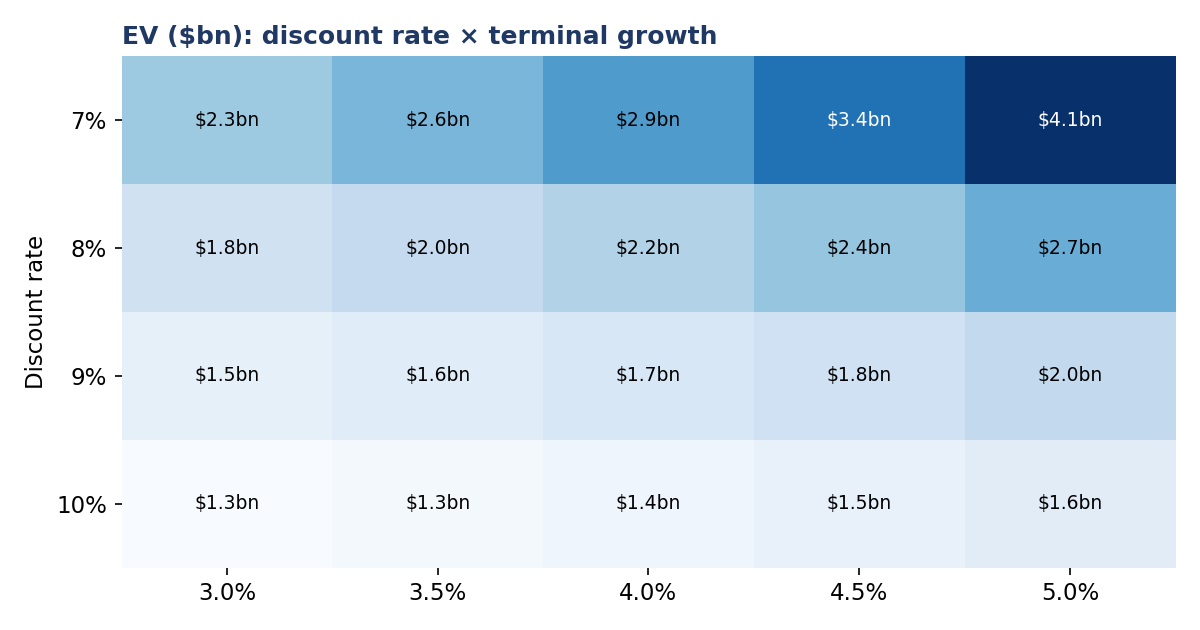

In [4]:
ex, go = sensitivity(inp)
display(ex.round(0)); display(go.round(0))
display(Image(charts.sensitivity_heatmap(ex, "EV ($bn): discount rate × exit multiple", "{:.0f}x", OUT / "sens_exit.png")))
display(Image(charts.sensitivity_heatmap(go, "EV ($bn): discount rate × terminal growth", "{:.1%}", OUT / "sens_gordon.png")))

## 3. Precedent transactions

Nine NFL deals, 2022–2026. Trailing revenue is the season before each deal, from each team's Forbes page. Minority and PE deals have printed at higher multiples (13–15x) than control deals (11.5x mean), which is unusual and says a lot about PE demand.

In [5]:
comps = load_comps()
display(comps[["team","date","buyer","stake","implied_value_mm","trailing_revenue_mm","ev_rev","type"]].round(2))
summ = comps_summary(comps); implied = implied_values(inp, summ)
display(implied.round(2))

,team,date,buyer,stake,implied_value_mm,trailing_revenue_mm,ev_rev,type
0,Seattle Seahawks,2026,Khosla family group,1.0,9600,659,14.6,Control
1,Denver Broncos,2022,Walton-Penner,1.0,4650,526,8.8,Control
2,Washington Commanders,2023,Josh Harris group,1.0,6050,545,11.1,Control
3,New York Giants,Oct 2025,Julia Koch,0.1,10300,707,14.6,Minority
4,Atlanta Falcons,Aug 2025,Arctos (PE),0.1,10600,612,17.3,PE minority
5,Cleveland Browns,May 2025,Arctos (PE),0.0,9000,685,13.1,PE minority
6,Las Vegas Raiders,Spring 2025,Egon Durban group,0.2,9900,779,12.7,Minority
7,Miami Dolphins,Mar 2025,Ares (PE),0.1,8100,656,12.3,PE minority
8,Buffalo Bills,2024,Arctos (PE),0.1,5800,552,10.5,PE minority


,ev_rev,implied_ev_mm,equity_mm,vs_forbes
control_mean,11.5,"7,430.9","7,282.3",-0.1
minority_pe_mean,13.4,"8,677.0","8,503.4",0.1
median,12.7,"8,209.8","8,045.6",0.0
low,8.8,"5,710.8","5,596.6",-0.3
high,17.3,"11,188.9","10,965.1",0.4
league_average,13.4,"8,656.4","8,483.3",0.1


## 4. The private-equity stake

Entry: 10% of equity after a 20% LP discount. Exit after six years with the discount narrowing to 10%. Half of free cash flow during the hold is distributed (owners usually reinvest, so this is generous).

,appreciation,entry,exit_equity_100pct,exit_proceeds,distributions,moic,irr,clears_hurdle
Bear,0.1,635.0,"10,637.7",957.4,20.6,1.5,0.1,False
Base,0.1,635.0,"14,062.7","1,265.6",20.6,2.0,0.1,False
Bull,0.1,635.0,"18,361.1","1,652.5",20.6,2.6,0.2,True


Break-even appreciation for a 15% IRR: 12.8%/yr
Break-even entry discount at 10%/yr growth: 30%


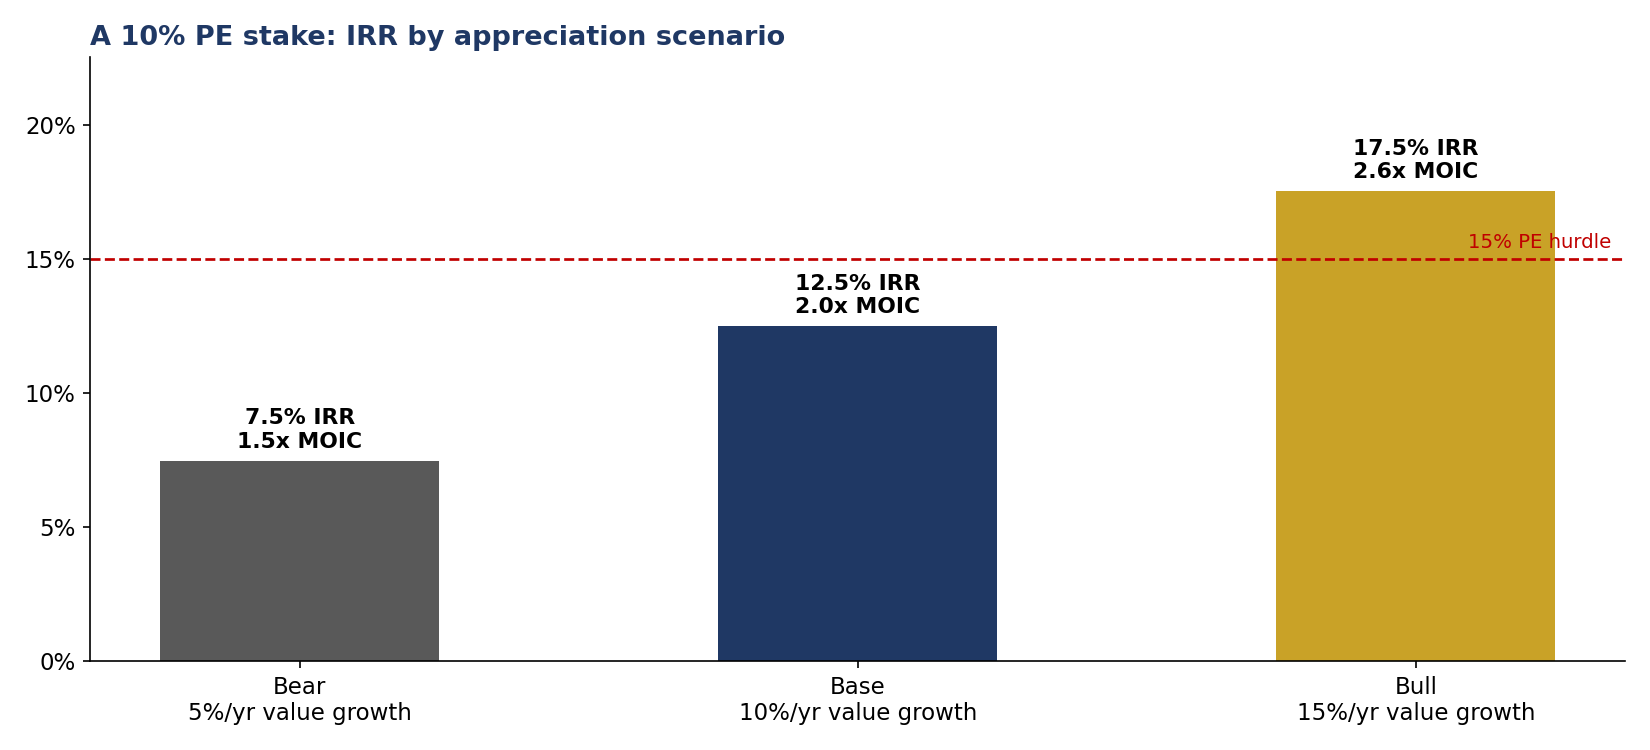

In [6]:
fcf_6 = df.loc[2026:2031, "fcf"].sum()
pe = pe_table(inp, fcf_6)
display(pe.T.round(3))
print(f"Break-even appreciation for a {inp.target_irr:.0%} IRR: {breakeven_growth(inp):.1%}/yr")
print(f"Break-even entry discount at {inp.appreciation['Base']:.0%}/yr growth: {breakeven_discount(inp, inp.appreciation['Base'], fcf_6):.0%}")
display(Image(charts.pe_irr(pe, inp, OUT / "pe_irr.png")))

## 5. Football field and the call

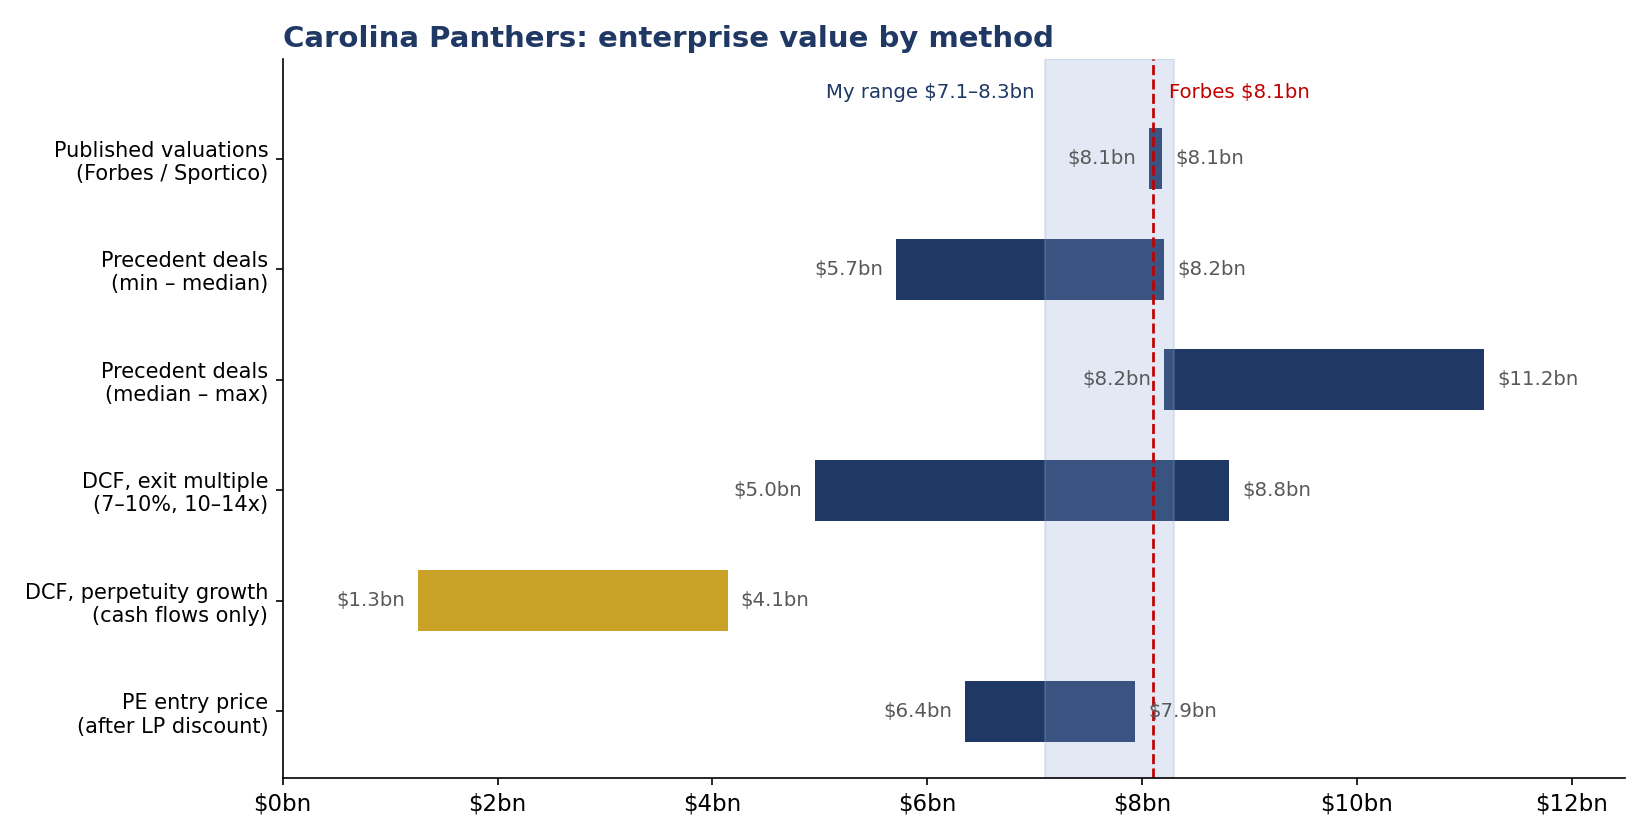

In [7]:
ranges = [
    ("Published valuations\n(Forbes / Sportico)", inp.sportico_value, inp.forbes_value),
    ("Precedent deals\n(min – median)", implied.loc["low","implied_ev_mm"], implied.loc["median","implied_ev_mm"]),
    ("Precedent deals\n(median – max)", implied.loc["median","implied_ev_mm"], implied.loc["high","implied_ev_mm"]),
    ("DCF, exit multiple\n(7–10%, 10–14x)", ex.values.min(), ex.values.max()),
    ("DCF, perpetuity growth\n(cash flows only)", go.values.min(), go.values.max()),
    ("PE entry price\n(after LP discount)", inp.equity_value*(1-inp.lp_discount), inp.equity_value),
]
display(Image(charts.football_field(ranges, inp, (7100, 8300), OUT / "football_field.png")))

### Recommendation

**Pass at the headline price; buy at a 30%+ LP discount or on a strong 2029 media outcome.** The base case earns 12.5%, short of a 15% hurdle. It clears the hurdle only if franchise values compound above 12.8% a year, or if the entry discount is 30% rather than 20%. Fair-value range: $7.1–8.3B.

### Try it yourself
Change any input and rerun. For example, `Inputs(media_uplift_2030=0.0, discount_rate=0.10)` is the bear case for the DCF; `Inputs(lp_discount=0.30)` is the entry that makes the PE math work.

In [8]:
for name, alt in {"No media uplift": Inputs(media_uplift_2030=0.0), "10% discount rate": Inputs(discount_rate=0.10), "30% LP discount": Inputs(lp_discount=0.30)}.items():
    d = project(alt); v = dcf_value(alt, d); p = pe_table(alt, d.loc[2026:2031, "fcf"].sum())
    print(f"{name:<20} EV exit ${v['ev_exit']:,.0f}mm   EV gordon ${v['ev_gordon']:,.0f}mm   base IRR {p['Base']['irr']:.1%}")

No media uplift      EV exit $6,380mm   EV gordon $1,296mm   base IRR 12.4%
10% discount rate    EV exit $5,844mm   EV gordon $1,390mm   base IRR 12.5%
30% LP discount      EV exit $6,980mm   EV gordon $2,163mm   base IRR 15.0%
